In [11]:
import tensorflow as tf
from tensorflow.keras import Model
import pn_classes
from pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder
import numpy as np
import h5py
from scipy.sparse import csr_matrix
import ccdm
from ccdm_initialize import initialize
from sionna.phy.fec.interleaving import RandomInterleaver, Deinterleaver
from sionna.phy.utils import ebnodb2no
from plotting import PlotBER
from sionna.phy.mapping import Constellation, Mapper, Demapper, BinarySource
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder, LDPCBPDecoder
from sionna.phy.channel import AWGN
import sionna as sn
from end_to_end_model import generate_ldpc_H_matrix, symbol_points_qam64
import os
import matplotlib.pyplot as plt
from scipy.io import loadmat
import time

# start_time = time.perf_counter()


In [12]:
# import tensorflow_probability as tfp

# class PTRS_Adder:
#     def __init__(self, path_to_ptrs_mat , num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size):
#         data = loadmat(path_to_ptrs_mat)
#
#         self.pilots = tf.cast(tf.reshape(tf.convert_to_tensor(data["pilots"][:num_ptrs_blocks*symbols_per_ptrs_block]),[num_ptrs_blocks*symbols_per_ptrs_block]), dtype = tf.complex64)
#
#         self.ptrs_indices, self.data_indices = self.get_ptrs_block_indices(block_size_ptrs,num_ptrs_blocks,symbols_per_ptrs_block)
#         # ptrs_indices_tensor = tf.convert_to_tensor(ptrs_indices)
#
#         ptrs_zero_row = tf.zeros_like(self.ptrs_indices)
#         ptrs_indices_2d = tf.transpose(tf.stack([ptrs_zero_row, self.ptrs_indices], axis=1),[0,1])
#         self.data_indices_exp = tf.expand_dims(self.data_indices, axis=1)
#
#         rgrid = tf.zeros([1,block_size_ptrs], dtype=tf.complex64)
#         rgrid = tf.tensor_scatter_nd_update(
#             rgrid,
#             ptrs_indices_2d,
#             self.pilots
#         )
#         self.resource_grid = tf.tile(rgrid, [batch_size, 1])
#
#     def __call__(self, x_mod):
#
#         # print('data_indices_exp :',self.data_indices_exp.shape)
#         # print('resource grid :',tf.transpose(self.resource_grid,[1, 0]).shape)
#         # print('x_mod :', tf.transpose(x_mod,[1, 0]).shape)
#
#         x_mod_w_ptrs = tf.transpose(tf.tensor_scatter_nd_update(
#             tf.transpose(self.resource_grid,[1, 0]),
#             self.data_indices_exp,
#             tf.transpose(x_mod,[1, 0])
#         ),[1, 0])
#
#         return x_mod_w_ptrs
#
#     def get_ptrs_block_indices(self, block_length, ptrs_blocks_per_block, samples_per_block):
#         edge = np.mod(block_length-ptrs_blocks_per_block*samples_per_block,ptrs_blocks_per_block-1)
#         block_distance = (block_length-samples_per_block*ptrs_blocks_per_block-edge)/(ptrs_blocks_per_block-1)
#         ptrs_block_indices = np.arange(np.floor(edge/2), np.floor(edge/2)+samples_per_block)
#
#         for n in range(1,ptrs_blocks_per_block):
#             ptrs_block_indices = np.concatenate([ptrs_block_indices, np.arange(ptrs_block_indices[-1]+block_distance+1, ptrs_block_indices[-1]+samples_per_block+block_distance+1)])
#
#         all_indices = np.arange(block_length)
#         data_indices = np.setdiff1d(all_indices, ptrs_block_indices)
#
#         return ptrs_block_indices.astype(int), data_indices.astype(int)
#
# class PN_Compensation:
#     def __init__(self, ptrs_indices, data_indices, block_size_ptrs, pilots, batch_size):
#         self.x_dense = tf.cast(tf.range(0, block_size_ptrs),tf.float32)
#         self.ptrs_avg_indices = tf.cast(tf.reduce_mean((tf.reshape(ptrs_indices,[-1, 8, 4])), axis =-1), tf.float32)
#         self.pilots = pilots
#         self.ptrs_indices = ptrs_indices
#         self.data_indices = data_indices
#         self.batch_size = batch_size
#
#     def __call__(self, y_down):
#         y_ptrs = tf.gather(y_down, self.ptrs_indices, axis=1)
#         phase_estimate = y_ptrs * tf.math.conj(self.pilots)/tf.cast(tf.square(tf.abs(self.pilots)), tf.complex64)
#         phase_estimate_mean = tf.reduce_mean(tf.reshape(phase_estimate,[self.batch_size, 8,4]), axis=-1)
#         phase_estimate_interp_r = tfp.math.interp_regular_1d_grid(x=self.x_dense, x_ref_min = self.ptrs_avg_indices[0,0]
#                                                                 ,x_ref_max = self.ptrs_avg_indices[0,-1],
#                                                                  y_ref= tf.math.real(phase_estimate_mean))
#         phase_estimate_interp_i = tfp.math.interp_regular_1d_grid(x=self.x_dense, x_ref_min = self.ptrs_avg_indices[0,0]
#                                                                 ,x_ref_max = self.ptrs_avg_indices[0,-1],
#                                                                  y_ref= tf.math.imag(phase_estimate_mean))
#         y_wpn_free = y_down / tf.complex(phase_estimate_interp_r,phase_estimate_interp_i)
#         y_data = tf.gather(y_wpn_free, self.data_indices, axis=1)
#         return y_wpn_free, y_data


class BICM_scheme(Model):

    def __init__(self, batch_size, num_bp_iter, use_dvb, symbol_points):
        super().__init__()

        self.use_dvb = use_dvb
        self.batch_size = batch_size
        llr_max_value = 1000.00
        self.channel = AWGN()
        self.num_bits_per_symbol = 6

        if self.use_dvb:
            r = 3 / 5
            n_ldpc = 16200
            self.k_ldpc = int(n_ldpc * r)

            parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc, rate=r, q=18, file_path="ldpccode_short_3_5.txt")
            H_csr = csr_matrix(parity_matrix[:, :self.k_ldpc])
            self.H_sparse = tf.sparse.SparseTensor(
                indices=np.vstack((H_csr.nonzero()[0], H_csr.nonzero()[1])).T.astype(np.int64),
                values=H_csr.data.astype(np.int32),
                dense_shape=H_csr.shape
            )
            self.H_sparse_test = csr_matrix(parity_matrix[:, :self.k_ldpc])
            batch_size_tf = tf.constant(batch_size, dtype=tf.int64)
            self.decoder = LDPCBPDecoder(parity_matrix,  # connect encoder (for shared code parameters)
                                         cn_update="boxplus-phi",  # use the exact boxplus function
                                         num_iter=num_bp_iter,
                                         llr_max=llr_max_value,
                                         hard_out=False)
            self.source = BinarySource()

        else:
            self.k_ldpc = 5949
            n_ldpc = 7932
            # self.k_ldpc = 3069
            # n_ldpc = 4092
            self.source = BinarySource()
            self.encoder = LDPC5GEncoder(self.k_ldpc, n_ldpc)
            self.siso_decoder = LDPC5GDecoder(self.encoder, return_infobits=False, num_iter=num_bp_iter, hard_out=False,
                                              llr_max=llr_max_value, return_state=True)
            self.decoder = LDPC5GDecoder(self.encoder, return_infobits=True, hard_out=True, num_iter=num_bp_iter,
                                         llr_max=llr_max_value, return_state=False)

        # initialize a random interleaver and corresponding deinterleaver
        self.interleaver = RandomInterleaver()
        self.deinterleaver = Deinterleaver(self.interleaver)

        probabilities = np.ones_like(symbol_points) / (2 ** self.num_bits_per_symbol)
        power = np.sum(probabilities * np.abs(symbol_points) ** 2)
        normalized_points = symbol_points / np.sqrt(power)
        constellation = Constellation("custom", num_bits_per_symbol=6, points=normalized_points)

        # mapper and demapper
        self.mapper = Mapper(constellation=constellation)
        self.demapper = Demapper("app", constellation=constellation)  # APP demapper
        self.num_symbols = int(n_ldpc / self.num_bits_per_symbol)

        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                              samples_per_symbol=4,
                                                              span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                              samples_per_symbol=4,
                                                              span_in_symbols=32)

        # num_ptrs_blocks = 32
        # symbols_per_ptrs_block = 4
        # block_size_ptrs = int(n_ldpc/self.num_bits_per_symbol) + 128
        # bandwidth = 960e3 * 4096
        # fc = 120e9
        # samples = 4 * (block_size_ptrs + 32)

        num_ptrs_blocks = 8
        symbols_per_ptrs_block = 4
        block_size_ptrs = int(n_ldpc/self.num_bits_per_symbol) + 32
        bandwidth = 960e3 * 4096
        fc = 120e9
        samples = 4 * (block_size_ptrs + 32)

        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset=self.rx_filter.length - 1,
                                                      num_symbols=tf.cast(block_size_ptrs, tf.int32))

        path_to_mat = "PreloadedMats/ptrs_CAZAC_4_32.mat"

        self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
        self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices,
                                             block_size_ptrs, self.ptrs_adder.pilots, batch_size)
        self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
        self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)

    @tf.function  # Graph execution to speed things up
    def __call__(self, batch_size, ebno_db):
        # calculate noise variance
        no = ebnodb2no(ebno_db,
                       num_bits_per_symbol=self.num_bits_per_symbol,
                       coderate=3 / 5)

        if self.use_dvb:
            b_stream = tf.cast(self.source([batch_size, self.k_ldpc]), tf.int32)  # generate random data
            p_bits = tf.transpose(tf.sparse.sparse_dense_matmul(self.H_sparse, tf.transpose(b_stream)))
            p_bits = tf.math.mod(p_bits, 2)
            p_bits = tf.math.mod(tf.math.cumsum(p_bits, axis=1), 2)
            codeword = tf.concat([b_stream, p_bits], axis=1)
        else:
            b_stream = tf.cast(self.source([batch_size, self.k_ldpc]), tf.float32)  # generate random data
            codeword = tf.cast(self.encoder(b_stream), tf.int32)

        c_int = self.interleaver(codeword)
        x = self.mapper(c_int)

        #######################
        # print(x.shape)
        ptrs_x_mod = self.ptrs_adder(x)

        x_up = self.upsampler(ptrs_x_mod)
        x_tx_filt = self.tx_filter(x_up)
        pn_out, _, _ = self.pn_tx(x_tx_filt)
        y_channel = self.channel(pn_out, no)
        y_channel_pn, _, _ = self.pn_rx(y_channel)
        y_rx_filt = self.rx_filter(y_channel_pn)
        y = self.downsampler(y_rx_filt)
        # print('y.shape: ',y.shape)
        _, y_data_vec = self.pn_compensate(y)

        #######################

        # mean_squared = tf.reduce_mean(tf.abs(x) ** 2)
        # print('meansquare :',mean_squared.numpy())
        # print('no :',no.numpy())
        # y = self.channel(x, no) # transmit over AWGN channel

        llr_ch = self.demapper(y_data_vec, no)  # demapp
        llr_deint = self.deinterleaver(llr_ch)
        if self.use_dvb:
            llr_u_stream = self.decoder(llr_deint)  # run LDPC decoder

            u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
            b_stream_hat = u_stream_hat[:, :self.k_ldpc]
        else:
            b_stream_hat = self.decoder(llr_deint)
        # tf.print(b_stream_hat.dtype)
        # tf.print(b_stream.dtype)
        return b_stream, b_stream_hat

class PAS_scheme(Model):

    def __init__(self, batch_size, num_bp_iter, const_symbol_points, p_basic):
        super().__init__()

        self.batch_size = 1
        self.num_bits_per_symbol = 6
        self.parity_k = 2 # Two bits represent parity bits, other four represent information

        r = 2/3   # m = 6 so (m-2)/m rate code is required here
        self.k_ldpc = 10800
        n_ldpc = 16200
        self.n_out = 2700

        self.binary_source = BinarySource()

        parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=15,file_path="ldpccode_short_2_3.txt")
        self.H_sparse = csr_matrix(parity_matrix[:, :self.k_ldpc])

        # p_basic = np.array([0.00622466, 0.01608852, 0.03347011, 0.02951173, 0.01565116, 0.03419713,
        #  0.07408216, 0.06683832, 0.03084535, 0.06940064, 0.14336276, 0.12366232,
        #  0.02854129, 0.06747344, 0.13703237, 0.12361801])

        [p_quant,self.k_input,self.n_i] = initialize(p_basic,self.n_out)

        probabilities = np.tile(p_basic,(1,(2**self.parity_k)))/(2**self.parity_k)
        power = np.sum(probabilities * np.abs(const_symbol_points)**2)
        normalized_points = const_symbol_points / np.sqrt(power)

        self.channel = AWGN()
        constellation = Constellation("custom", num_bits_per_symbol=6, points = normalized_points)
        self.mapper = Mapper(constellation=constellation)
        self.demapper = Demapper("app", constellation=constellation) # APP demapper

        num_bp_iter = 50
        llr_max_value = 120

        self.decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                cn_update="boxplus-phi", # use the exact boxplus function
                                num_iter=num_bp_iter,
                                llr_max=llr_max_value,
                               hard_out=True)

        bit_labels = np.array([[int(b) for b in format(i, f'0{6}b')] for i in range(64)])
        p_b1 = np.reshape(np.matmul(probabilities,bit_labels),(-1))
        self.prior = np.log(p_b1 / (1.0 - p_b1))

        self.bit_positions = np.arange((self.num_bits_per_symbol-self.parity_k)-1, -1, -1)

        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)

        num_ptrs_blocks = 32
        symbols_per_ptrs_block = 4
        block_size_ptrs = self.n_out+ 4*32
        bandwidth = 960e3*4096
        fc = 120e9
        samples = 4*(block_size_ptrs+32)

        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,
                                                 num_symbols=tf.cast(block_size_ptrs, tf.int32))

        path_to_mat = "PreloadedMats/ptrs_CAZAC_4_32.mat"

        self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
        self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs, self.ptrs_adder.pilots,batch_size)
        self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
        self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    # No Graph execution possible due to sequential CCDM Encode and Decode
    # Due to this no attempt was made to use tensorflow implementation
    def __call__(self, batch_size, ebno_db):
        no = ebnodb2no(ebno_db,
                       num_bits_per_symbol=3.6,
                       coderate=1)

        b_stream = np.array(self.binary_source([self.k_input]),np.int64)
        code_symbols = np.array(ccdm.encode(b_stream, self.n_out, self.n_i))
        reverse_map = (((code_symbols[:, None]-1) & (1 << np.arange(self.num_bits_per_symbol-self.parity_k)[::-1])) > 0).astype(int)
        enc_input = np.reshape(reverse_map,((self.num_bits_per_symbol-self.parity_k)*self.n_out))
        parity_bits = self.H_sparse.dot(enc_input) % 2  # mod 2 because XOR over GF(2)
        parity_bits = np.mod(np.cumsum(parity_bits) , 2)
        parity_reshaped = np.reshape(parity_bits,(-1,self.parity_k))
        mapper_input_matrix = np.concatenate((parity_reshaped,reverse_map),axis=1)
        mapper_input = np.reshape(mapper_input_matrix,(self.num_bits_per_symbol*self.n_out))
        x = self.mapper(mapper_input)

        #########################

        ptrs_x_mod = self.ptrs_adder(tf.expand_dims(x,axis=0))

        x_up = self.upsampler(ptrs_x_mod)
        x_tx_filt = self.tx_filter(x_up)
        pn_out, _, _ = self.pn_tx(x_tx_filt)
        y_channel = self.channel(pn_out, no)
        y_channel_pn, _, _ = self.pn_rx(y_channel)
        y_rx_filt = self.rx_filter(y_channel_pn)
        y = self.downsampler(y_rx_filt)
        # print('y.shape: ',y.shape)
        _, y_data_vec = self.pn_compensate(y)

        #########################
        # mean_squared = tf.reduce_mean(tf.abs(x) ** 2)
        # print('meansquare',mean_squared.numpy())
        # print('no :',no.numpy())
        # y = self.channel(x, no)
        llr_ch = self.demapper(y_data_vec, no, self.prior)
        llr_reshaped = np.reshape(llr_ch,(-1,self.num_bits_per_symbol))
        llr_parity_comp = np.reshape(llr_reshaped[:,:self.parity_k],(-1))
        llr_amplitude_comp = np.reshape(llr_reshaped[:,self.parity_k:],(-1))
        codeword_llr = np.hstack((llr_amplitude_comp, llr_parity_comp))
        decoded_bits = tf.cast(self.decoder(codeword_llr),tf.int64).numpy()
        info_bits_reshaped = np.reshape(decoded_bits[:self.k_ldpc],(-1,self.num_bits_per_symbol-self.parity_k))
        # Use bitwise left shift to compute powers of two
        shifted_bits = info_bits_reshaped << self.bit_positions
        # Compute the integer representation using bitwise operations
        code_symbols_retrieved = np.sum(shifted_bits, axis=-1)+1
        # tf.print('ccdm input: ', code_symbols_retrieved.shape)
        decoded_bits_ccdmdec = ccdm.decode(code_symbols_retrieved, self.n_i, self.k_input)
        missing = self.k_input - len(decoded_bits_ccdmdec)
        if missing > 0:
            decoded_bits_ccdmdec.extend([0] * missing)
        # tf.print('ccdm :',np.array(decoded_bits_ccdmdec).shape)
        # tf.print('b_stream :',b_stream.shape)

        return b_stream, decoded_bits_ccdmdec


In [49]:
extr_const_data = np.load(f"const_points_extracted.npz")

const_points_wo_constr = extr_const_data['const_points_wo_constr']

In [53]:
batch_size = 40
num_bp_iter = 50
use_dvb = False

ber_plot_bicm = PlotBER("ber_plot_bicm")

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_qam64)

ber_plot_bicm.simulate(model_bicm,  # the function have defined previously
                       ebno_dbs=np.arange(5.0, 13.0, 0.2),  # sim SNR range
                       legend='Test BICM',
                       add_bler=True,
                       add_ber=True,
                       max_mc_iter=250,
                       num_target_block_errors=100,
                       batch_size=batch_size,
                       soft_estimates=False,
                       early_stop=True,
                       show_fig=False,
                       forward_keyboard_interrupt=False)

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, const_points_wo_constr)

ber_plot_bicm.simulate(model_bicm,  # the function have defined previously
                       ebno_dbs=np.arange(5.0, 13.0, 0.2),  # sim SNR range
                       legend='Test BICM',
                       add_bler=True,
                       add_ber=True,
                       max_mc_iter=250,
                       num_target_block_errors=100,
                       batch_size=batch_size,
                       soft_estimates=False,
                       early_stop=True,
                       show_fig=False,
                       forward_keyboard_interrupt=False)

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.0 | 1.8504e-01 | 1.0000e+00 |       22716 |      122760 |           40 |          40 |         0.8 |iter: 0/250
      5.0 | 1.8570e-01 | 1.0000e+00 |       45593 |      245520 |           80 |          80 |         0.9 |iter: 1/250
      5.0 | 1.8559e-01 | 1.0000e+00 |       68349 |      368280 |          120 |         120 |         0.9 |iter: 2/250
      5.0 | 1.8559e-01 | 1.0000e+00 |       68349 |      368280 |          120 |         120 |         0.9 |reached target block errors
      5.2 | 1.8141e-01 | 1.0000e+00 |       22270 |      122760 |           40 |          40 |         0.1 |iter: 0/250
      5.2 | 1.8131e-01 | 1.0000e+00 |       44516 |      245520 |           80 |          80 |         0.2 |iter: 1/250
      5.2

(<tf.Tensor: shape=(40,), dtype=float32, numpy=
 array([0.279893  , 0.27669165, 0.2721652 , 0.2679673 , 0.26244977,
        0.26061964, 0.2580455 , 0.25181654, 0.24797437, 0.24376561,
        0.23909526, 0.23253775, 0.22880688, 0.22572228, 0.22019659,
        0.21392962, 0.21030737, 0.20446399, 0.2007277 , 0.19566363,
        0.19257902, 0.18437602, 0.18121538, 0.17547518, 0.16874932,
        0.1630037 , 0.15682633, 0.15107799, 0.145145  , 0.13768871,
        0.13407733, 0.1233518 , 0.11635984, 0.11212936, 0.10272618,
        0.0908765 , 0.07993918, 0.06916477, 0.04714076, 0.0310883 ],
       dtype=float32)>,
 <tf.Tensor: shape=(40,), dtype=float32, numpy=
 array([1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.     

In [54]:
bicm_ber = np.array(ber_plot_bicm.ber)
bicm_snr = np.array(ber_plot_bicm.snr)

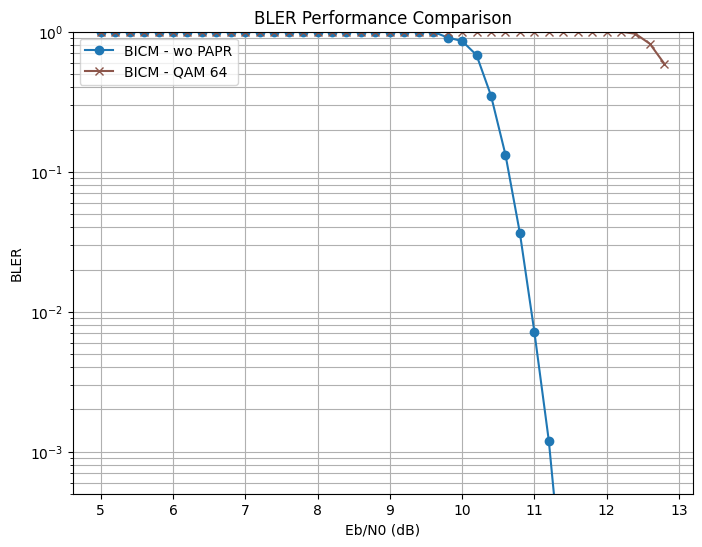

In [55]:
plt.figure(figsize=(8,6))

# [6.4, 6.8, 7.2, 7.6, 8.0]

# plt.semilogy(bicm_snr[0,:], bicm_ber[1,:], marker='o', label="BICM - PAPR 5.5")
# plt.semilogy(bicm_snr[0,:], bicm_ber[3,:], marker='o', label="BICM - PAPR 6.0")
# plt.semilogy(bicm_snr[0,:], bicm_ber[1,:], marker='o', label="BICM - PAPR 6.5")
plt.semilogy(bicm_snr[0,:], bicm_ber[1,:], marker='o', label="BICM - wo PAPR")
plt.semilogy(bicm_snr[0,:], bicm_ber[3,:], marker='x', label="BICM - QAM 64",color = 'tab:brown')


plt.xlabel("Eb/N0 (dB)")
plt.ylabel("BLER")
plt.ylim(5e-4, 1)
plt.title("BLER Performance Comparison")
plt.grid(True, which="both")
plt.legend()

plt.show()

In [64]:
RESULTS_DIR = "results_gcs_benchmark"

snr_list = [13]
papr_list = [5.5, 6.0, 6.5, 7.0]

batch_size = 40
num_bp_iter = 50
use_dvb = False


ber_plot_bicm = PlotBER("ber_plot_bicm")

for snr_db in snr_list:
    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        plotname = f"papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")
        points = data["constellation_points"]

        model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points)

        ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                                  ebno_dbs=np.arange(5.0, 13.0, 0.2), # sim SNR range
                                  legend=plotname,
                                  add_bler = True,
                                  add_ber = True,
                                  max_mc_iter=250,
                                  num_target_block_errors=100,
                                  batch_size=batch_size,
                                  soft_estimates=False,
                                  early_stop=True,
                                  show_fig=False,
                                  forward_keyboard_interrupt=False)

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_qam64)

ber_plot_bicm.simulate(model_bicm,  # the function have defined previously
                       ebno_dbs=np.arange(5.0, 13.0, 0.2),  # sim SNR range
                       legend='Test BICM',
                       add_bler=True,
                       add_ber=True,
                       max_mc_iter=250,
                       num_target_block_errors=100,
                       batch_size=batch_size,
                       soft_estimates=False,
                       early_stop=True,
                       show_fig=False,
                       forward_keyboard_interrupt=False)

data_no_constraint = np.load(f"no_constraint_gcs.npz")
points = data_no_constraint["constellation_points"]

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points)

ber_plot_bicm.simulate(model_bicm,  # the function have defined previously
                       ebno_dbs=np.arange(5.0, 13.0, 0.2),  # sim SNR range
                       legend='Test BICM',
                       add_bler=True,
                       add_ber=True,
                       max_mc_iter=250,
                       num_target_block_errors=100,
                       batch_size=batch_size,
                       soft_estimates=False,
                       early_stop=True,
                       show_fig=False,
                       forward_keyboard_interrupt=False)



EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.0 | 2.0982e-01 | 1.0000e+00 |       25758 |      122760 |           40 |          40 |         1.0 |iter: 0/250
      5.0 | 2.0980e-01 | 1.0000e+00 |       51511 |      245520 |           80 |          80 |         1.1 |iter: 1/250
      5.0 | 2.0937e-01 | 1.0000e+00 |       77107 |      368280 |          120 |         120 |         1.2 |iter: 2/250
      5.0 | 2.0937e-01 | 1.0000e+00 |       77107 |      368280 |          120 |         120 |         1.2 |reached target block errors
      5.2 | 2.0639e-01 | 1.0000e+00 |       25336 |      122760 |           40 |          40 |         0.1 |iter: 0/250
      5.2 | 2.0479e-01 | 1.0000e+00 |       50279 |      245520 |           80 |          80 |         0.2 |iter: 1/250
      5.2

(<tf.Tensor: shape=(40,), dtype=float32, numpy=
 array([1.82301506e-01, 1.79442272e-01, 1.75127625e-01, 1.70783103e-01,
        1.67769089e-01, 1.63310528e-01, 1.58050939e-01, 1.55115679e-01,
        1.49980992e-01, 1.46823063e-01, 1.41471162e-01, 1.35665804e-01,
        1.32358536e-01, 1.26496151e-01, 1.22944497e-01, 1.20609321e-01,
        1.15281850e-01, 1.07708812e-01, 1.01246335e-01, 9.54898447e-02,
        8.42864141e-02, 7.95563161e-02, 6.86298460e-02, 5.68181835e-02,
        3.81129831e-02, 2.33069938e-02, 9.12053045e-03, 2.50553060e-03,
        7.57265429e-04, 6.07038128e-05, 3.48647768e-06, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       dtype=float32)>,
 <tf.Tensor: shape=(40,), dtype=float32, numpy=
 array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 

In [65]:
bicm_ber = np.array(ber_plot_bicm.ber)
bicm_snr = np.array(ber_plot_bicm.snr)

In [72]:
np.savez(
    f"no_dvb_bler.npz",
    bicm_ber=bicm_ber,
    bicm_snr=bicm_snr
)

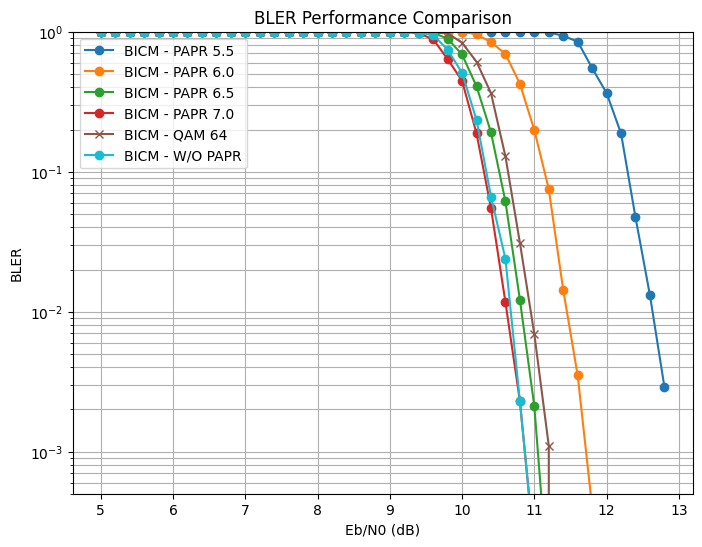

In [67]:
plt.figure(figsize=(8,6))

# [6.4, 6.8, 7.2, 7.6, 8.0]

plt.semilogy(bicm_snr[0,:], bicm_ber[1,:], marker='o', label="BICM - PAPR 5.5")
plt.semilogy(bicm_snr[0,:], bicm_ber[3,:], marker='o', label="BICM - PAPR 6.0")
plt.semilogy(bicm_snr[0,:], bicm_ber[5,:], marker='o', label="BICM - PAPR 6.5")
plt.semilogy(bicm_snr[0,:], bicm_ber[7,:], marker='o', label="BICM - PAPR 7.0")
plt.semilogy(bicm_snr[0,:], bicm_ber[9,:], marker='x', label="BICM - QAM 64", color = 'tab:brown')
plt.semilogy(bicm_snr[0,:], bicm_ber[11,:], marker='o', label="BICM - W/O PAPR", color = 'tab:cyan')

plt.xlabel("Eb/N0 (dB)")
plt.ylabel("BLER")
plt.ylim(5e-4, 1)
plt.title("BLER Performance Comparison")
plt.grid(True, which="both")
plt.legend()

plt.show()

### With DVB unconstrained GCS

In [78]:
ber_plot_bicm = PlotBER("ber_plot_bicm")

In [79]:
batch_size = 40
num_bp_iter = 50
use_dvb = True

In [80]:
data_no_constraint = np.load(f"no_constraint_gcs.npz")
points = data_no_constraint["constellation_points"]

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, points)

ber_plot_bicm.simulate(model_bicm,  # the function have defined previously
                       ebno_dbs=np.arange(5.0, 13.0, 0.1),  # sim SNR range
                       legend='Test BICM',
                       add_bler=True,
                       add_ber=True,
                       max_mc_iter=250,
                       num_target_block_errors=100,
                       batch_size=batch_size,
                       soft_estimates=False,
                       early_stop=True,
                       show_fig=False,
                       forward_keyboard_interrupt=False)


EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.0 | 1.5073e-01 | 1.0000e+00 |       58605 |      388800 |           40 |          40 |         2.0 |iter: 0/250
      5.0 | 1.5096e-01 | 1.0000e+00 |      117387 |      777600 |           80 |          80 |         2.3 |iter: 1/250
      5.0 | 1.5073e-01 | 1.0000e+00 |      175817 |     1166400 |          120 |         120 |         2.6 |iter: 2/250
      5.0 | 1.5073e-01 | 1.0000e+00 |      175817 |     1166400 |          120 |         120 |         2.6 |reached target block errors
      5.1 | 1.4958e-01 | 1.0000e+00 |       58158 |      388800 |           40 |          40 |         0.3 |iter: 0/250
      5.1 | 1.5003e-01 | 1.0000e+00 |      116664 |      777600 |           80 |          80 |         0.6 |iter: 1/250
      5.1

(<tf.Tensor: shape=(80,), dtype=float32, numpy=
 array([1.50734738e-01, 1.49742797e-01, 1.46898150e-01, 1.45208329e-01,
        1.42894372e-01, 1.39401585e-01, 1.37993827e-01, 1.34651914e-01,
        1.33064985e-01, 1.29984573e-01, 1.28482506e-01, 1.25228047e-01,
        1.22539438e-01, 1.20270059e-01, 1.16568074e-01, 1.14612482e-01,
        1.11646950e-01, 1.08931758e-01, 1.05838478e-01, 1.01133399e-01,
        9.60313752e-02, 8.94718766e-02, 7.82133043e-02, 6.19135797e-02,
        4.67206798e-02, 2.96270568e-02, 1.57486703e-02, 8.11739545e-03,
        4.19152947e-03, 1.35547353e-03, 5.38878608e-04, 1.68940329e-04,
        9.28703739e-05, 1.66152258e-05, 8.13786028e-06, 8.23045241e-08,
        3.08641965e-08, 1.02880655e-07, 4.11522620e-08, 1.02880655e-08,
        6.17283931e-08, 3.08641965e-08, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.000000

In [81]:
bicm_ber = np.array(ber_plot_bicm.ber)
bicm_snr = np.array(ber_plot_bicm.snr)

np.savez(
    f"dvb_bicm_bler.npz",
    bicm_ber=bicm_ber,
    bicm_snr=bicm_snr
)

### Unconstrained PAS

In [13]:
data = np.load(f"no_constraint_pn_120GHz.npz")
points = data["constellation_points"]

probabilities = data["constellation_probabilities"]
prob_reshape = np.reshape(probabilities,[4,16])
prob_basic_set = prob_reshape[0,:]*4

In [14]:
plotname = 'BER plot'

In [15]:

ber_plot_pas = PlotBER("ber_plot_pas")

pas_model = PAS_scheme(1, 50, points, prob_basic_set)

ber_plot_pas.simulate(pas_model, # the function have defined previously
                          ebno_dbs=np.arange(5.0, 13.0, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=1000,
                          num_target_block_errors=10,
                          batch_size=1,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)





EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.0 | 5.0316e-01 | 1.0000e+00 |        4855 |        9649 |            1 |           1 |         2.4 |iter: 0/1000
      5.0 | 5.0415e-01 | 1.0000e+00 |        9729 |       19298 |            2 |           2 |         3.3 |iter: 1/1000
      5.0 | 5.0447e-01 | 1.0000e+00 |       14603 |       28947 |            3 |           3 |         4.3 |iter: 2/1000
      5.0 | 5.0308e-01 | 1.0000e+00 |       19417 |       38596 |            4 |           4 |         5.1 |iter: 3/1000
      5.0 | 5.0277e-01 | 1.0000e+00 |       24256 |       48245 |            5 |           5 |         6.0 |iter: 4/1000
      5.0 | 5.0195e-01 | 1.0000e+00 |       29060 |       57894 |            6 |           6 |         6.9 |iter: 5/1000
      5.0 | 5.0109e

(<tf.Tensor: shape=(80,), dtype=float32, numpy=
 array([0.5019795 , 0.50163746, 0.49869415, 0.5007358 , 0.49878743,
        0.49801016, 0.49672505, 0.50106746, 0.49994817, 0.4997202 ,
        0.49794796, 0.5027775 , 0.49953362, 0.4993678 , 0.49840397,
        0.4981656 , 0.49564722, 0.44517097, 0.21900056, 0.20008118,
        0.1530227 , 0.09488652, 0.033972  , 0.02488566, 0.00557817,
        0.00276122, 0.00098135, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,


In [16]:
pas_ber = ber_plot_pas.ber
pas_snr = ber_plot_pas.snr

In [17]:
np.savez(
    f"pas_dvb_bler_120GHz.npz",
    pas_ber=pas_ber,
    pas_snr=pas_snr
)

In [15]:
batch_size = 40
num_bp_iter = 50
use_dvb = False

ber_plot_bicm = PlotBER("ber_plot_bicm")

# for snr_db in snr_list:
#     for papr_db in papr_list:
#         exp_name = f"snr_{snr_db}_papr_{papr_db}"
#         plotname = f"papr_{papr_db}"
#         data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")
#         points = data["constellation_points"]

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_qam64)

ber_plot_bicm.simulate(model_bicm,  # the function have defined previously
                       ebno_dbs=np.arange(5.0, 13.0, 0.1),  # sim SNR range
                       legend='Test BICM',
                       add_bler=True,
                       add_ber=True,
                       max_mc_iter=250,
                       num_target_block_errors=100,
                       batch_size=batch_size,
                       soft_estimates=False,
                       early_stop=True,
                       show_fig=False,
                       forward_keyboard_interrupt=False)



EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.0 | 1.8040e-01 | 1.0000e+00 |       22146 |      122760 |           40 |          40 |         2.8 |iter: 0/250
      5.0 | 1.8176e-01 | 1.0000e+00 |       44625 |      245520 |           80 |          80 |         2.9 |iter: 1/250
      5.0 | 1.8204e-01 | 1.0000e+00 |       67041 |      368280 |          120 |         120 |         3.0 |iter: 2/250
      5.0 | 1.8204e-01 | 1.0000e+00 |       67041 |      368280 |          120 |         120 |         3.0 |reached target block errors
      5.1 | 1.8165e-01 | 1.0000e+00 |       22299 |      122760 |           40 |          40 |         0.1 |iter: 0/250
      5.1 | 1.8181e-01 | 1.0000e+00 |       44637 |      245520 |           80 |          80 |         0.2 |iter: 1/250
      5.1

(<tf.Tensor: shape=(80,), dtype=float32, numpy=
 array([1.82038128e-01, 1.81362003e-01, 1.79578036e-01, 1.76273495e-01,
        1.75396442e-01, 1.73851416e-01, 1.71410337e-01, 1.70221031e-01,
        1.67660475e-01, 1.65719017e-01, 1.62569240e-01, 1.62009880e-01,
        1.59688279e-01, 1.57252640e-01, 1.55713052e-01, 1.53176934e-01,
        1.52598560e-01, 1.50733143e-01, 1.47591501e-01, 1.46570548e-01,
        1.42779946e-01, 1.42312914e-01, 1.38924181e-01, 1.35407835e-01,
        1.35101005e-01, 1.33803084e-01, 1.30900398e-01, 1.27905399e-01,
        1.27093509e-01, 1.23750947e-01, 1.22947216e-01, 1.20818399e-01,
        1.16718255e-01, 1.14269033e-01, 1.12373739e-01, 1.09560661e-01,
        1.08205713e-01, 1.03736289e-01, 1.00502335e-01, 9.86233279e-02,
        9.58184004e-02, 9.05207992e-02, 9.02737081e-02, 8.49408060e-02,
        7.99853355e-02, 7.73569047e-02, 7.37916827e-02, 6.58928007e-02,
        6.02150522e-02, 5.65656573e-02, 4.57613766e-02, 3.41051631e-02,
        2.687520

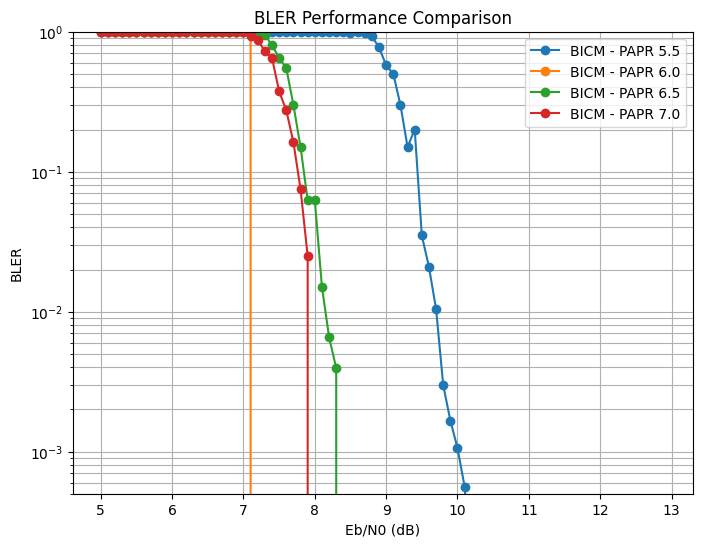

In [17]:
bicm_ber.shape

TensorShape([80])

In [18]:
bicm_bler.shape

TensorShape([80])

In [19]:
bicm_snr[0].shape

()

In [20]:
bicm_snr

array([ 5. ,  5.1,  5.2,  5.3,  5.4,  5.5,  5.6,  5.7,  5.8,  5.9,  6. ,
        6.1,  6.2,  6.3,  6.4,  6.5,  6.6,  6.7,  6.8,  6.9,  7. ,  7.1,
        7.2,  7.3,  7.4,  7.5,  7.6,  7.7,  7.8,  7.9,  8. ,  8.1,  8.2,
        8.3,  8.4,  8.5,  8.6,  8.7,  8.8,  8.9,  9. ,  9.1,  9.2,  9.3,
        9.4,  9.5,  9.6,  9.7,  9.8,  9.9, 10. , 10.1, 10.2, 10.3, 10.4,
       10.5, 10.6, 10.7, 10.8, 10.9, 11. , 11.1, 11.2, 11.3, 11.4, 11.5,
       11.6, 11.7, 11.8, 11.9, 12. , 12.1, 12.2, 12.3, 12.4, 12.5, 12.6,
       12.7, 12.8, 12.9])

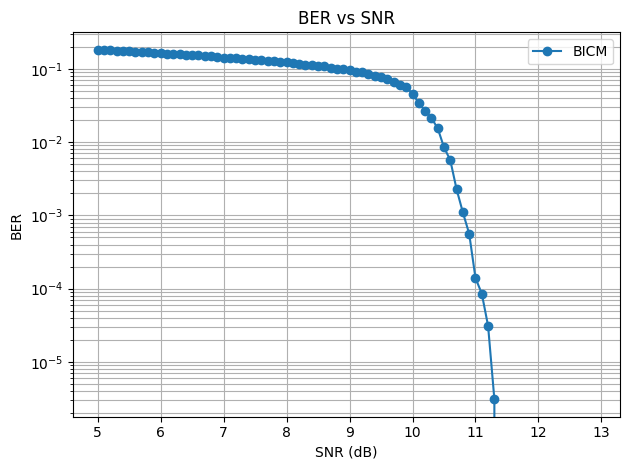

In [21]:
plt.figure()
plt.semilogy(bicm_snr, bicm_ber, 'o-', label="BICM")
plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.title("BER vs SNR")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()
# plt.savefig(os.path.join(output_folder, "BER_plot.png"), dpi=300)
plt.close()

### PAS BLER Check

In [97]:
data = np.load(f"results_pn_entropy_120GHz_64apsk1/snr_13_papr_6.4.npz")
points = data["constellation_points"]

probabilities = data["constellation_probabilities"]
prob_reshape = np.reshape(probabilities,[4,16])
prob_basic_set = prob_reshape[0,:]*4

In [98]:
ber_plot_pas = PlotBER("ber_plot_pas")
plotname = '6.4 PAPR constellation check'

In [99]:
pas_model = PAS_scheme(1, 50, points, prob_basic_set)

In [89]:
input_stream,output_stream,outcome = pas_model(1,10.0)

In [90]:
input_stream = np.array(input_stream)
output_stream = np.array(output_stream)

In [91]:
np.sum(np.square(input_stream - output_stream))

0

In [93]:
assert np.array_equal(np.array(input_stream), np.array(output_stream))

In [94]:
output_stream.dtype

dtype('int64')

In [72]:
import numpy as np
import matplotlib.pyplot as plt

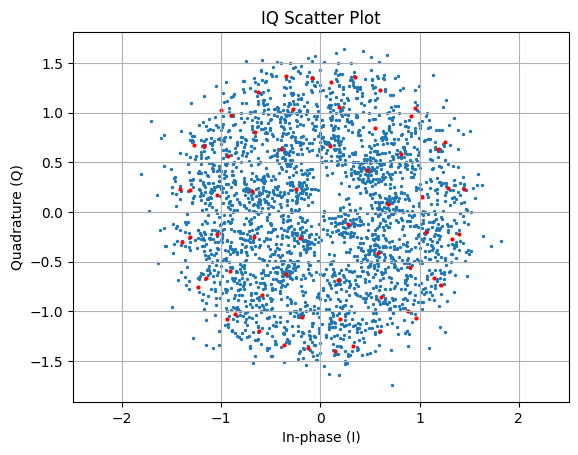

In [95]:
# Extract I and Q
I = np.real(outcome)
Q = np.imag(outcome)

# Plot
plt.figure()
plt.scatter(I, Q, s=2)

plt.scatter(np.real(points), np.imag(points), s=4, color='r')

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("IQ Scatter Plot")
plt.grid()
plt.axis('equal')
plt.show()

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      7.5 | 4.9663e-01 | 1.0000e+00 |        4791 |        9647 |            1 |           1 |         1.0 |iter: 0/1000
      7.5 | 4.9668e-01 | 1.0000e+00 |        9583 |       19294 |            2 |           2 |         1.9 |iter: 1/1000
      7.5 | 4.9781e-01 | 1.0000e+00 |       14407 |       28941 |            3 |           3 |         2.8 |iter: 2/1000
      7.5 | 4.9907e-01 | 1.0000e+00 |       19258 |       38588 |            4 |           4 |         3.7 |iter: 3/1000
      7.5 | 5.0111e-01 | 1.0000e+00 |       24171 |       48235 |            5 |           5 |         4.6 |iter: 4/1000
      7.5 | 5.0057e-01 | 1.0000e+00 |       28974 |       57882 |            6 |           6 |         5.5 |iter: 5/1000
      7.5 | 5.0002e

(<tf.Tensor: shape=(10,), dtype=float32, numpy=
 array([0.49988598, 0.49920183, 0.500736  , 0.4998756 , 0.41424796,
        0.26430207, 0.14857501, 0.09355924, 0.06068796, 0.03786271],
       dtype=float32)>,
 <tf.Tensor: shape=(10,), dtype=float32, numpy=
 array([1.        , 1.        , 1.        , 1.        , 0.8333333 ,
        0.5555556 , 0.3030303 , 0.18867925, 0.12345679, 0.07692308],
       dtype=float32)>)

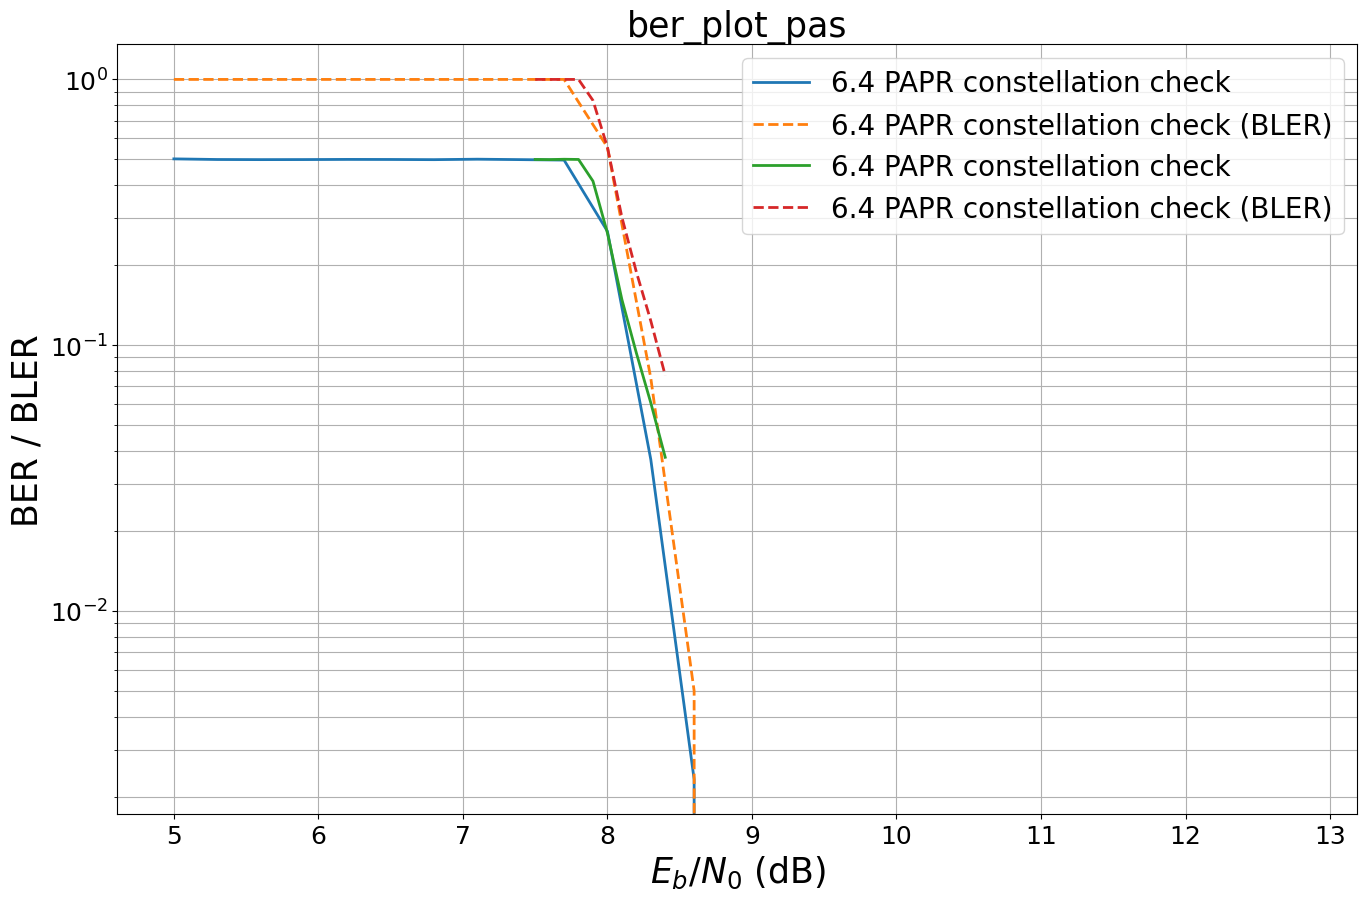

In [101]:
ber_plot_pas.simulate(pas_model, # the function have defined previously
                          ebno_dbs=np.arange(7.5, 8.5, 0.1), #np.arange(4.6, 6.2, 0.04), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=1000,
                          num_target_block_errors=10,
                          batch_size=1,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=True,
                          forward_keyboard_interrupt=False)


In [33]:
batch_size = 2
num_bp_iter = 50
use_dvb = False

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_qam64)

In [34]:
model_bicm(batch_size,8.0)

meansquare : 1.0205278
no : 0.044024806


(<tf.Tensor: shape=(2, 3069), dtype=float32, numpy=
 array([[0., 1., 0., ..., 1., 1., 0.],
        [0., 0., 1., ..., 1., 0., 1.]], dtype=float32)>,
 <tf.Tensor: shape=(2, 3069), dtype=float32, numpy=
 array([[0., 0., 0., ..., 1., 1., 1.],
        [0., 0., 1., ..., 1., 0., 0.]], dtype=float32)>)

### Evaluating with exact constellation points from Dileepa

In [111]:
from scipy.io import loadmat

In [112]:
data = loadmat('com_data_dileepa.mat')

z1 = data['z1'].squeeze()
z2 = data['z2'].squeeze()
z3 = data['z3'].squeeze()
z4 = data['z4'].squeeze()

In [113]:
z1.shape

(64,)

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.0 | 2.1313e-01 | 1.0000e+00 |       50716 |      237960 |           40 |          40 |         1.1 |iter: 0/250
      5.0 | 2.1271e-01 | 1.0000e+00 |      101233 |      475920 |           80 |          80 |         1.3 |iter: 1/250
      5.0 | 2.1262e-01 | 1.0000e+00 |      151788 |      713880 |          120 |         120 |         1.4 |iter: 2/250
      5.0 | 2.1262e-01 | 1.0000e+00 |      151788 |      713880 |          120 |         120 |         1.4 |reached target block errors
      5.2 | 2.0965e-01 | 1.0000e+00 |       49889 |      237960 |           40 |          40 |         0.1 |iter: 0/250
      5.2 | 2.0870e-01 | 1.0000e+00 |       99323 |      475920 |           80 |          80 |         0.3 |iter: 1/250
      5.2

(<tf.Tensor: shape=(40,), dtype=float32, numpy=
 array([1.86466917e-01, 1.82638541e-01, 1.80199757e-01, 1.74890742e-01,
        1.70813024e-01, 1.67694852e-01, 1.63757220e-01, 1.59986272e-01,
        1.56106070e-01, 1.52779177e-01, 1.46310300e-01, 1.43676803e-01,
        1.39388978e-01, 1.36947393e-01, 1.32841647e-01, 1.27148822e-01,
        1.23983026e-01, 1.18556343e-01, 1.12115480e-01, 1.08623296e-01,
        1.03230238e-01, 9.66450945e-02, 9.47119966e-02, 8.41121748e-02,
        7.93606788e-02, 7.20457211e-02, 6.08421601e-02, 4.31396030e-02,
        3.47739123e-02, 2.11099908e-02, 1.31754167e-02, 8.63440428e-03,
        3.87981744e-03, 2.52045481e-03, 1.22107193e-03, 7.41323747e-04,
        4.67974896e-04, 2.00974959e-04, 1.04538580e-04, 4.16708681e-05],
       dtype=float32)>,
 <tf.Tensor: shape=(40,), dtype=float32, numpy=
 array([1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1. 

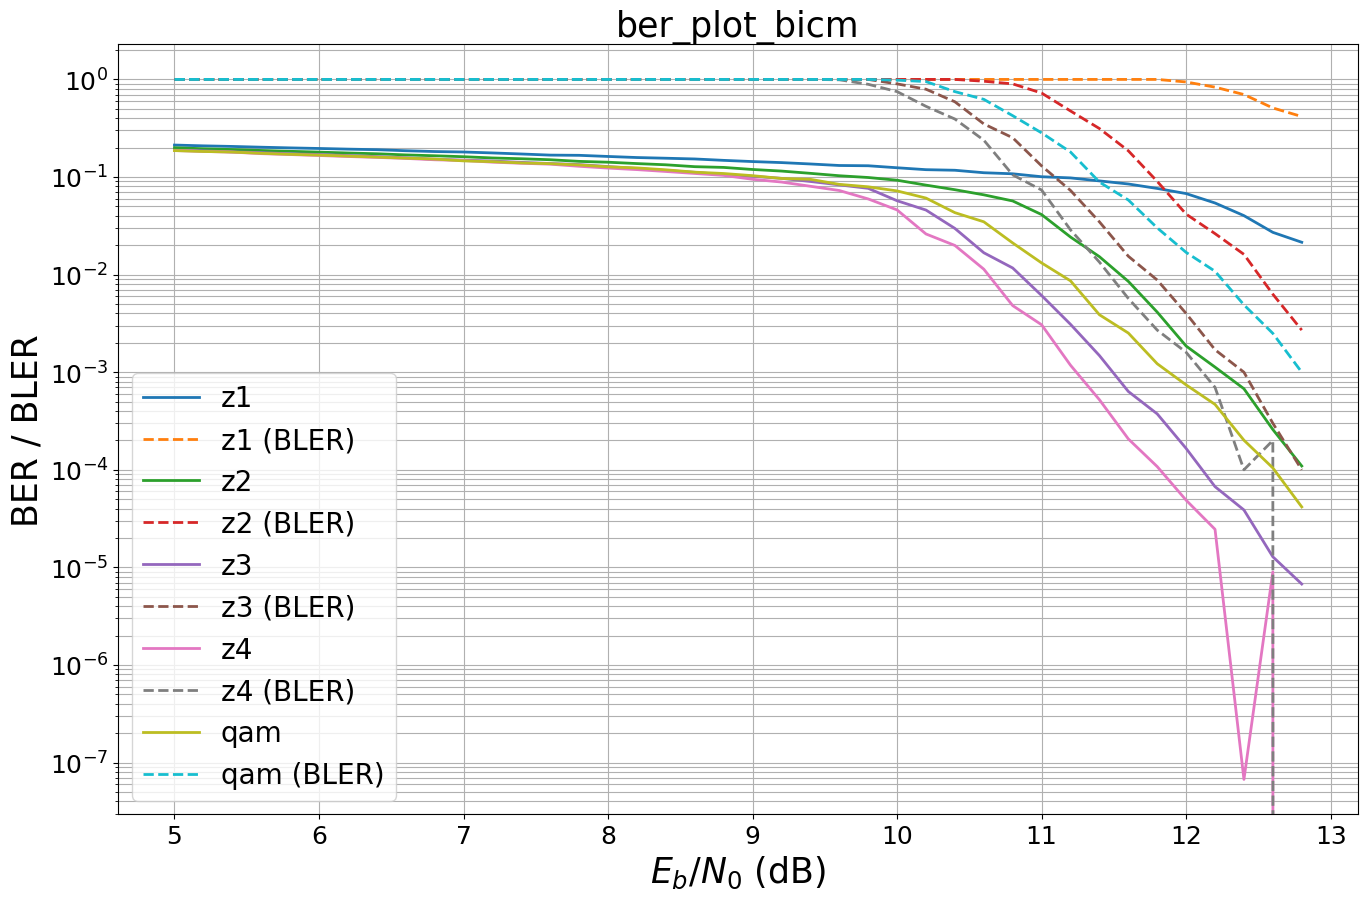

In [145]:
batch_size = 40
num_bp_iter = 50
use_dvb = False

ber_plot_bicm = PlotBER("ber_plot_bicm")

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, z1)
plotname = 'z1'

ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(5.0, 13.0, 0.2), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=100,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, z2)
plotname = 'z2'

ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(5.0, 13.0, 0.2), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=100,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, z3)
plotname = 'z3'

ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(5.0, 13.0, 0.2), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=100,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, z4)
plotname = 'z4'

ber_plot_bicm.simulate(model_bicm, # the function have defined previously
                          ebno_dbs=np.arange(5.0, 13.0, 0.2), # sim SNR range
                          legend=plotname,
                          add_bler = True,
                          add_ber = True,
                          max_mc_iter=250,
                          num_target_block_errors=100,
                          batch_size=batch_size,
                          soft_estimates=False,
                          early_stop=True,
                          show_fig=False,
                          forward_keyboard_interrupt=False)

model_bicm = BICM_scheme(batch_size, num_bp_iter, use_dvb, symbol_points_qam64)
plotname = 'qam'

ber_plot_bicm.simulate(model_bicm,  # the function have defined previously
                       ebno_dbs=np.arange(5.0, 13.0, 0.2),  # sim SNR range
                       legend= plotname,
                       add_bler=True,
                       add_ber=True,
                       max_mc_iter=250,
                       num_target_block_errors=100,
                       batch_size=batch_size,
                       soft_estimates=False,
                       early_stop=True,
                       show_fig=True,
                       forward_keyboard_interrupt=False)


In [146]:
bicm_ber = np.array(ber_plot_bicm.ber)
bicm_snr = np.array(ber_plot_bicm.snr)

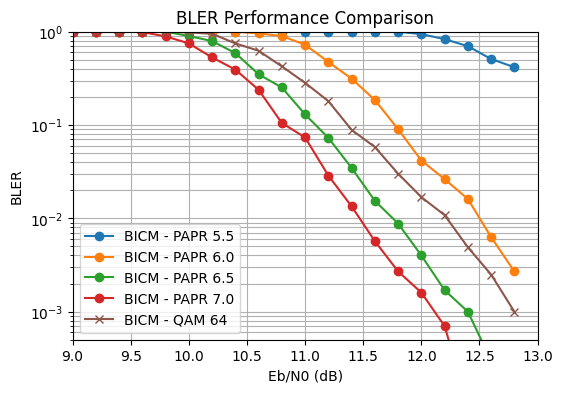

In [147]:
plt.figure(figsize=(6,4))

# [6.4, 6.8, 7.2, 7.6, 8.0]

plt.semilogy(bicm_snr[0,:], bicm_ber[1,:], marker='o', label="BICM - PAPR 5.5")
plt.semilogy(bicm_snr[0,:], bicm_ber[3,:], marker='o', label="BICM - PAPR 6.0")
plt.semilogy(bicm_snr[0,:], bicm_ber[5,:], marker='o', label="BICM - PAPR 6.5")
plt.semilogy(bicm_snr[0,:], bicm_ber[7,:], marker='o', label="BICM - PAPR 7.0")
plt.semilogy(bicm_snr[0,:], bicm_ber[9,:], marker='x', label="BICM - QAM 64", color = 'tab:brown')
# plt.semilogy(bicm_snr[0,:], bicm_ber[11,:], marker='o', label="BICM - W/O PAPR", color = 'tab:cyan')

plt.xlabel("Eb/N0 (dB)")
plt.ylabel("BLER")
plt.ylim(5e-4, 1)
plt.xlim(9, 13)
plt.title("BLER Performance Comparison")
plt.grid(True, which="both")
plt.legend()

plt.show()

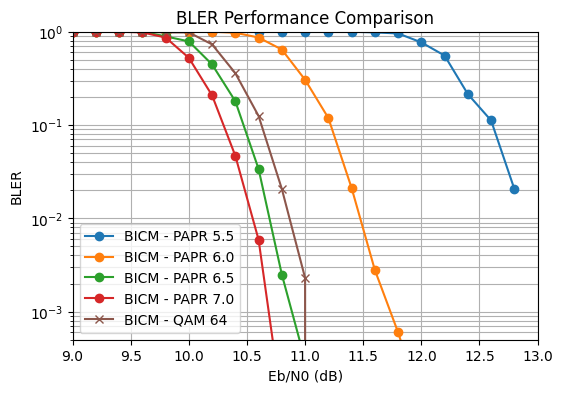

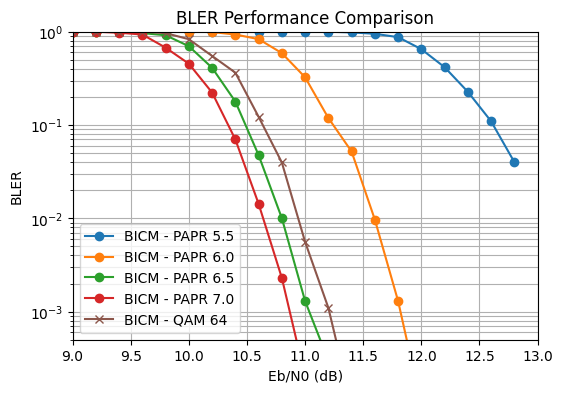

In [127]:
num_coded_bits = (4096 - 32 * (4)) * 6

In [130]:
tbconfig = sn.phy.nr.utils.calculate_tb_size(
target_tb_size=num_coded_bits*3/4,
target_coderate=3/4,
modulation_order=6,
num_coded_bits=num_coded_bits,
verbose=True)

Modulation order: 6
Target coderate: 0.750
Effective coderate: 0.753
Number of layers: 1
------------------
Info bits per TB: 17928
TB CRC length: 24
Total number of coded TB bits: 23808
------------------
Info bits per CB: 6008
Number of CBs: 3
CB CRC length: 24
Output codeword lengths: [7932 7938 7938]


In [ ]:






self.tb_size = tbconfig[0]

# Create TBEncoder
tb_encoder = sn.phy.nr.TBEncoder(
target_tb_size=self.tb_size,
num_coded_bits=self.num_coded_bits,
target_coderate=PARAMETERS["CODE_RATE"],
num_bits_per_symbol=PARAMETERS["BITS_PER_SYMBOL"],
channel_type="PDSCH",
codeword_index=0,  # not supported for PUSCH
use_scrambler=True,
verbose=True)
tb_decoder = sn.phy.nr.TBDecoder(tb_encoder, num_bp_iter=50)